# Demo: Modeling of Aircraft Landing Contingency Scenarios

```
Copyright © 2024, United States Government, as represented by the Administrator of the National Aeronautics and Space Administration. All rights reserved.

The “"Fault Model Design tools - fmdtools version 2"” software is licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at http://www.apache.org/licenses/LICENSE-2.0. 

Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.
```

In [19]:
from fmdtools_examples.airspacelib.aircraft_landing.model_main import AircraftLanding
from fmdtools.sim import propagate

This model is made up of the following functions:

- aviate, the movement of the aircraft
- control_flight, the operation of the aircraft
- modify_environment, the external conditions that modify the environment of the airport (e.g., by placing obstacles)

and the following flows:

- aircraft_dofs: the local aerodynamic states of the aircraft
- aircraft_trajectory: the global location and velocity 
- controls: the control commands (e.g., control surfaces, throttle, brakes)

These interact as shown below:

(<Figure size 1200x1000 with 1 Axes>, <Axes: >)

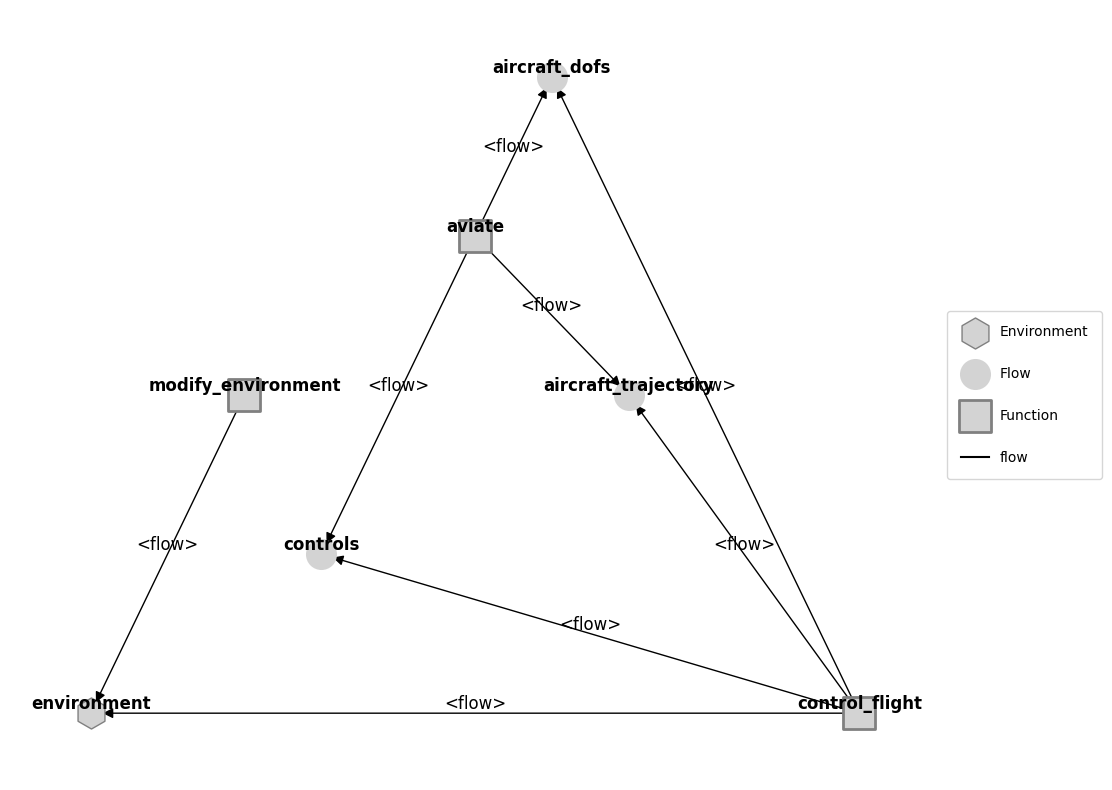

In [2]:
acl = AircraftLanding()
aclg = acl.as_modelgraph()
aclg.draw()

The scenario modelled is landing at Moffett Federal Airfield. Data about Moffett Field was taken from OpenStreetMap to develop this map environment of runways as shown below:

(<Figure size 400x400 with 1 Axes>,
 <Axes: title={'center': 'Moffett Field'}, xlabel='meters', ylabel='meters'>)

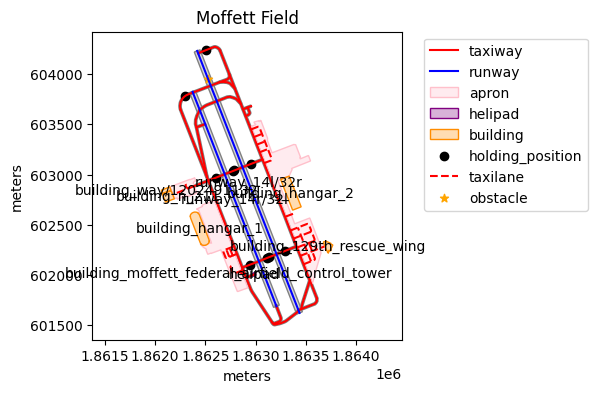

In [3]:
from fmdtools_examples.airspacelib.aircraft_landing.model_environment import MoffettField

mf = MoffettField()
mf.show_infrastructure()

The aerodynamic model is a simple 6DOF flight simulation that has been roughly tuned to match a 737.

For modeling simplicity, it is assumed that when the aircraft lands, the landing gear takes over and there isn't a chance to take off again. Additionally, ground effects are not included.

In [4]:
from fmdtools_examples.airspacelib.aircraft_landing.model_aviate import Aviate

ff = Aviate(track='all')
ff.aircraft_trajectory.s.z=10000
ff(time='end')


Below are a couple images showing how the trajectory changes over time with a strong application of the elevator at t=30. Note that the shown oscillation is a Phugoid mode which can be avoided with the proper application of control input algorithms:

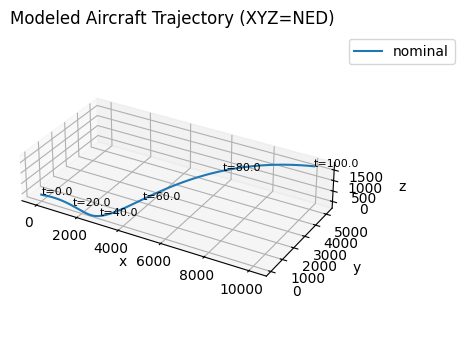

In [16]:
fig, ax = ff.h.plot_trajectories("aircraft_dofs.s.xe", "aircraft_dofs.s.ye", "aircraft_dofs.s.ze",
                                 time_groups=['nominal'], time_ticks=20.0,
                                 title="Modeled Aircraft Trajectory (XYZ=NED)")
ax.set_aspect("equal")

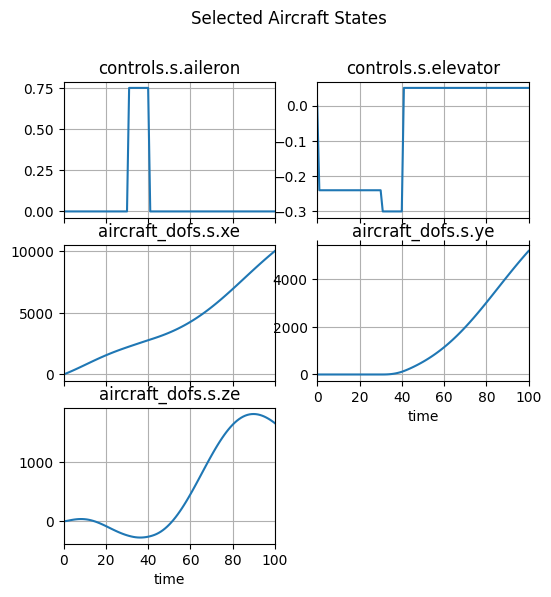

In [18]:
fig, ax = ff.h.plot_line("controls.s.aileron", "controls.s.elevator", "aircraft_dofs.s.xe", "aircraft_dofs.s.ye", "aircraft_dofs.s.ze",
                         title="Selected Aircraft States")

## Combined Model

When combined in a single model we get the following overall behavior:


In [ ]:
res, hist = propagate.nominal(acl)

In 2D you can see the aircraft approach the 14L runway from the Northeast (over the bay):

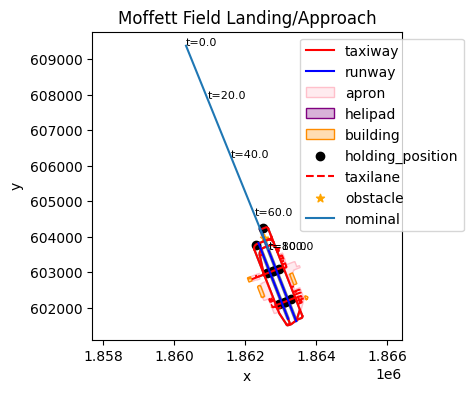

In [29]:
fig, ax = acl.flows['environment'].ga.show_infrastructure(overlay_labels=False,
                                                        title="Moffett Field Landing/Approach",
                                                        legend=False)
fig, ax = hist.plot_trajectories('flows.aircraft_trajectory.s.x',
                        'flows.aircraft_trajectory.s.y',
                        fig=fig, ax=ax, time_groups=['nominal'],
                        time_ticks=20.0, 
                        legend = dict(bbox_to_anchor = (0.65, 1)))
#ax.set_xticklabels([])
#ax.set_yticklabels([])

In 3D you can also see the descent. Note the differing scale of the z axis and the x/y:

(<Figure size 500x500 with 1 Axes>,
 <Axes3D: title={'center': 'False Abort at Time t=40.0'}, xlabel='East/West', ylabel='North/south', zlabel='Elevation above runway (meters)'>)

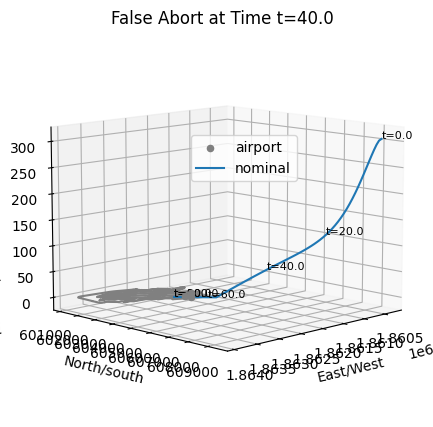

In [32]:
fig, ax = acl.flows['environment'].ga.show_as_one_color(figsize=(5,5), z=True, legend=True,)
ax.view_init(elev=10, azim=45, roll=0)
hist.plot_trajectories('flows.aircraft_trajectory.s.x',
                        'flows.aircraft_trajectory.s.y',
                        'flows.aircraft_trajectory.s.z',
                        fig=fig, ax=ax, time_groups=['nominal', "faulty"],
                        xlabel="East/West",
                        ylabel="North/south",
                        zlabel="Elevation above runway (meters)",
                        time_ticks=20.0,
                        title="False Abort at Time t=40.0",
                        legend = dict(bbox_to_anchor = (0.4,0.75)))

We can also see the various states of interest:

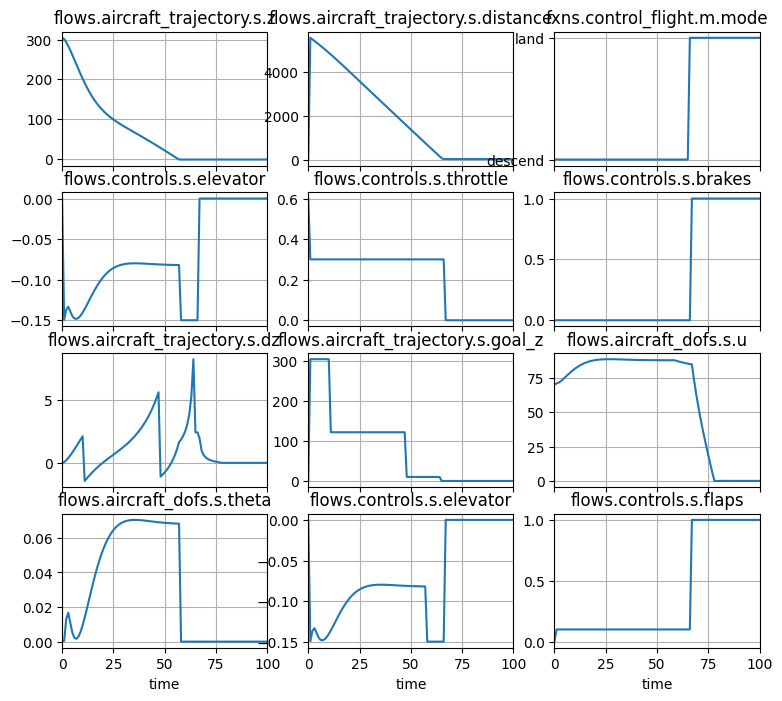

In [33]:
fig, ax = hist.plot_line('flows.aircraft_trajectory.s.z',
                'flows.aircraft_trajectory.s.distance',
                'fxns.control_flight.m.mode',
                'flows.controls.s.elevator',
                'flows.controls.s.throttle',
                'flows.controls.s.brakes',
                'flows.aircraft_trajectory.s.dz',
                'flows.aircraft_trajectory.s.goal_z',
                'flows.aircraft_dofs.s.u',
                'flows.aircraft_dofs.s.theta',
                'flows.controls.s.elevator',
                'flows.controls.s.flaps', cols=3)

## Risk and Resilience Study

The goal of thus model is to study risks having to do with runway object avoidance.

The two main hazardous modes of interest for this study are:

- False Object Avoidance, where the aircraft performs a go-around maneuver to avoid a non-existent object on the runway, and
- Object on Runway with No Avoidance, where the aircraft operator fails to identify objects on the runway

## Hazardous Mode: False Object Avoidance

In the False object avoidance scenario the aircraft performs a go-around maneuver as shown below:

In [39]:
res, hist = propagate.one_fault(acl, 'control_flight', "false_abort", time=40)

(<Figure size 500x500 with 1 Axes>,
 <Axes3D: title={'center': 'False Abort at Time t=40.0'}, xlabel='East/West', ylabel='North/south', zlabel='Elevation above runway (meters)'>)

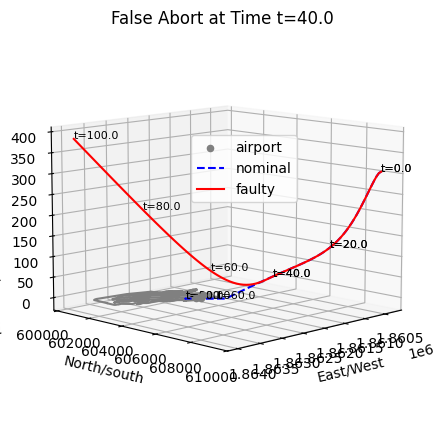

In [40]:
fig, ax = acl.flows['environment'].ga.show_as_one_color(figsize=(5,5), z=True, legend=True,)
ax.view_init(elev=10, azim=45, roll=0)
hist.plot_trajectories('flows.aircraft_trajectory.s.x',
                        'flows.aircraft_trajectory.s.y',
                        'flows.aircraft_trajectory.s.z',
                        fig=fig, ax=ax, time_groups=['nominal', "faulty"],
                        xlabel="East/West",
                        ylabel="North/south",
                        zlabel="Elevation above runway (meters)",
                        time_ticks=20.0,
                        title="False Abort at Time t=40.0",
                        legend = dict(bbox_to_anchor = (0.4,0.75)))

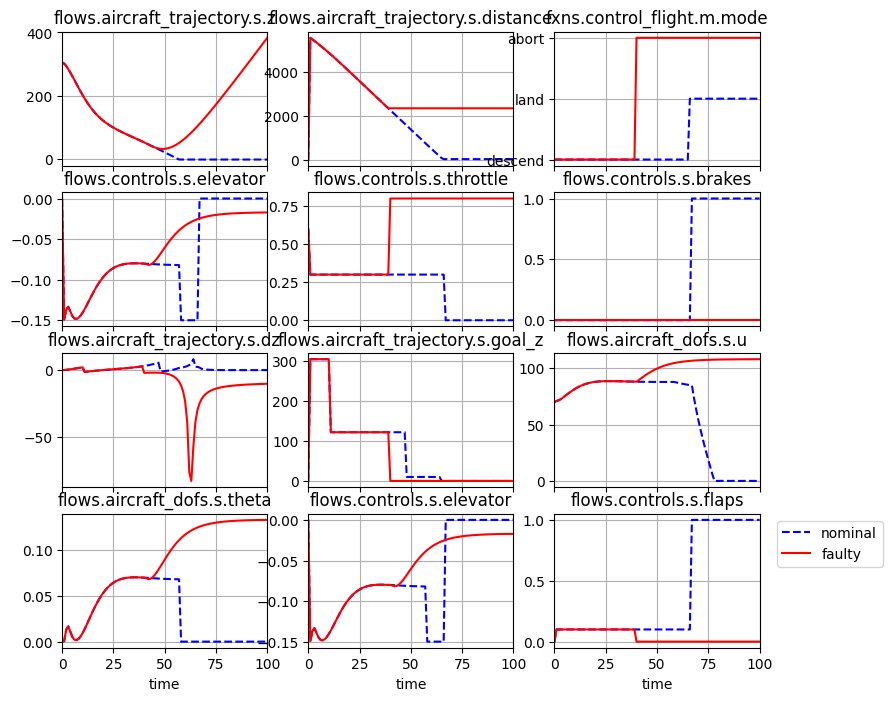

In [41]:
fig, ax = hist.plot_line('flows.aircraft_trajectory.s.z',
                'flows.aircraft_trajectory.s.distance',
                'fxns.control_flight.m.mode',
                'flows.controls.s.elevator',
                'flows.controls.s.throttle',
                'flows.controls.s.brakes',
                'flows.aircraft_trajectory.s.dz',
                'flows.aircraft_trajectory.s.goal_z',
                'flows.aircraft_dofs.s.u',
                'flows.aircraft_dofs.s.theta',
                'flows.controls.s.elevator',
                'flows.controls.s.flaps', cols=3)

Future work will study potential hazards and metrics to quantify the risk of unnecessary avoidance.

Of interest will be quantifying the risk of late go around maneuvers and sudden avoidance, e.g.:

- Avoidance times at which unnecessary tail strikes and bounces would be expected

- Potential for post-avoidance stalls and disorientation

## Hazardous Mode: Object on Runway with No Avoidance or Late Avoidance

(TBD)

Future work will study potential hazards and metrics to quantify the risk of not avoiding runway obstacles.

Of interest will be quantifying:

- Runway locations where avoidance is necessary
- Risks of late avoidance (e.g., how late is "too late" for an avoidance maneuver to be successful or have an appropriate amount of response time)